**Live Deployment Link:** [https://mubashir-ml-assignment-two.mellowllama2.chatgpt.site/?task=titanic](https://mubashir-ml-assignment-two.mellowllama2.chatgpt.site/?task=titanic)

The demo is currently owner-private. For an instructor-accessible public Python deployment, use the included Streamlit app and replace this link after deploying.

---
# Titanic Passenger Survival Prediction System

**Mubashir Ali**  
**Registration No.: Fa24-bse-140**  
**Assignment 2 - AIC354 - Fall 2026**


## Setup
Keep `sample-data.csv` beside this notebook. Install `requirements.txt`, open the notebook in Jupyter or VS Code, and run its cells in order. Each code cell is provided without comments or explanatory docstrings.


## Approach
The instructor's Titanic sample, four categorical attributes, LabelEncoder, ordered 80/20 split and SVC model are retained. Each learning step is shown separately.

## Introduction

##### **Definition** A binary classification ML task that predicts whether a passenger survived (1) or did not survive (0) the Titanic disaster using their attributes (e.g., class, sex, age, fare, etc.)
##### **Application** It is mainly used for learning data science, testing ML algorithms, and gaining insights into survival factors like gender and class.

##  Input and Output

###  Inputs (Features / Attributes)

| **Input Feature/Attribute**  |      **Possible Values**          |
| ------------ | ---------------------------------- |
| **PClass**   | First, Second, Third               |
| **Gender**   | Male, Female                       |
| **Sibling**  | Zero, One, Two, Three                     |
| **Embarked** | Southampton, Cherbourg, Queenstown |

### Output (Prediction)

| **Output Attribute** | **Possbile Values** |
| -------------------- | ------------------------- |
| **Survived**         | Yes, No                   |

### Examples (Titanic Dataset)

| PClass | Gender | Sibling | Embarked    | Survived |
| :----: | :----: | :-----: | :---------- | :------: |
|  Third |  Male  |   One   | Southampton |    No    |
| Second | Female |   Zero  | Southampton |    Yes   |
|  Third |  Male  |   Zero  | Southampton |    No    |
|  Third | Female |  Three  | Southampton |    Yes   |
|  Third |  Male  |   Zero  | Queenstown  |    No    |

## Developer & System Information

| Field | Details |
|---|---|
| Student Name | Mubashir Ali |
| Registration No. | Fa24-bse-140 |
| Course | AIC354 Machine Learning Fundamentals |
| Institution | COMSATS University Islamabad, Lahore Campus |
| Instructor | Dr. Rao Muhammad Adeel Nawab |
| Semester | Fall 2026 |
| Program Name | titanic_deployment |
| IDE | Jupyter Notebook |
| Programming Language | Python 3.12 |
| Libraries | NumPy, Pandas, Pickle, scikit-learn, PrettyTable, Matplotlib, Seaborn |


##  Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Train the Label Encoder
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - **Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) — NEW**
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
    - Step 8.5.1: Apply Model and Return Prediction to the User
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- **Step 10: Deploy Your Model as a Public Web App (NEW)**
  - Step 10.1: Why Deploy a Model?
  - Step 10.2: Create a GitHub Account and Repository
  - Step 10.3: Write a Simple Web App
  - Step 10.4: Create a Streamlit Community Cloud Account
  - Step 10.5: Deploy Your App
  - Step 10.6: Troubleshooting Common Issues
  - Step 10.7: Share Your Live Link


These are illustrative examples; no real reviewers or collected feedback are claimed.

## Code – Titanic Prediction Survival

###  Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
sample_data = pd.read_csv('sample-data.csv')
print('\n\nSample Data:')
print('============\n')
pd.set_option('display.max_rows', None, 'display.max_columns', None)
print(sample_data)



Sample Data:

    PClass  Gender Sibling     Embarked Survived
0    Third    Male     One  Southampton       No
1   Second  Female    Zero  Southampton      Yes
2    Third    Male    Zero  Southampton       No
3    Third  Female   Three  Southampton      Yes
4    Third    Male    Zero   Queenstown       No
5    First  Female   Three  Southampton      Yes
6    Third    Male    Zero  Southampton       No
7    Third    Male    Zero  Southampton      Yes
8    First    Male    Zero  Southampton       No
9   Second    Male    Zero  Southampton      Yes
10   Third    Male     One   Queenstown       No
11   First    Male    Zero    Cherbourg      Yes
12   First    Male    Zero    Cherbourg       No
13  Second  Female    Zero  Southampton      Yes
14  Second    Male    Zero  Southampton       No
15   Third    Male     One    Cherbourg      Yes
16   Third    Male     Two    Cherbourg       No
17   Third    Male    Zero  Southampton      Yes
18   Third    Male    Zero  Southampton       No
19  

### Step 3: Understand and Pre-process Sample Data

####  Step 3.1: Understand Sample Data

In [3]:
print('\n\nAttributes in Sample Data:')
print('==========================\n')
print(sample_data.columns)
print('\n\nNumber of Instances in Sample Data:', sample_data['PClass'].count())
print('========================================\n')



Attributes in Sample Data:

Index(['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived'], dtype='object')


Number of Instances in Sample Data: 100



#### Step 3.2: Pre-process Sample Data
o   Sample Data is already Preprocessed
o   No Preprocessing needs to be Performed

#### Step 4: Feature Extraction
o   Features are already Extracted
o   No Feature Extraction needs to be Performed

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [4]:
pclass = pd.DataFrame({'Pclass': ['First', 'Second', 'Third']})
gender = pd.DataFrame({'Gender': ['Male', 'Female']})
sibling = pd.DataFrame({'Sibling': ['Zero', 'One', 'Two', 'Three']})
embarked = pd.DataFrame({'Embarked': ['Southampton', 'Cherbourg', 'Queenstown']})
survived = pd.DataFrame({'Survived': ['Yes', 'No']})
pclass_label_encoder = LabelEncoder()
gender_label_encoder = LabelEncoder()
sibling_label_encoder = LabelEncoder()
embarked_label_encoder = LabelEncoder()
survived_label_encoder = LabelEncoder()
pclass_label_encoder.fit(np.ravel(pclass))
gender_label_encoder.fit(np.ravel(gender))
sibling_label_encoder.fit(np.ravel(sibling))
embarked_label_encoder.fit(np.ravel(embarked))
survived_label_encoder.fit(np.ravel(survived))

#### Step 5.2: Label Encode the Output

In [5]:
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()
print('\n\nSurvived Attribute After Label Encoding:')
print('========================================\n')
sample_data['encoded_survived'] = survived_label_encoder.transform(sample_data['Survived'])
print(sample_data[['Survived', 'encoded_survived']])
sample_data_encoded_output[['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']] = sample_data[['PClass', 'Gender', 'Sibling', 'Embarked', 'encoded_survived']]
sample_data_encoded_output.to_csv('sample-data-encoded-output.csv', index=False, header=True)
print('\nSaved: sample-data-encoded-output.csv')



Survived Attribute After Label Encoding:

   Survived  encoded_survived
0        No                 0
1       Yes                 1
2        No                 0
3       Yes                 1
4        No                 0
5       Yes                 1
6        No                 0
7       Yes                 1
8        No                 0
9       Yes                 1
10       No                 0
11      Yes                 1
12       No                 0
13      Yes                 1
14       No                 0
15      Yes                 1
16       No                 0
17      Yes                 1
18       No                 0
19      Yes                 1
20       No                 0
21      Yes                 1
22       No                 0
23      Yes                 1
24       No                 0
25      Yes                 1
26       No                 0
27      Yes                 1
28       No                 0
29      Yes                 1
30       No               

#### Step 5.3: Label Encode the Input

In [6]:
sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded_output['encoded_pclass'] = pclass_label_encoder.transform(sample_data_encoded_output['PClass'])
sample_data_encoded_output['encoded_gender'] = gender_label_encoder.transform(sample_data_encoded_output['Gender'])
sample_data_encoded_output['encoded_sibling'] = sibling_label_encoder.transform(sample_data_encoded_output['Sibling'])
sample_data_encoded_output['encoded_embarked'] = embarked_label_encoder.transform(sample_data_encoded_output['Embarked'])
sample_data_encoded[['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']] = sample_data_encoded_output[['encoded_pclass', 'encoded_gender', 'encoded_sibling', 'encoded_embarked', 'Survived']]
sample_data_encoded = sample_data_encoded.astype(int)
print('\n\nSample Data after Label Encoding:')
print('=================================\n')
print(sample_data_encoded)
sample_data_encoded.to_csv('sample-data-encoded.csv', index=False, header=True)



Sample Data after Label Encoding:

    PClass  Gender  Sibling  Embarked  Survived
0        2       1        0         2         0
1        1       0        3         2         1
2        2       1        3         2         0
3        2       0        1         2         1
4        2       1        3         1         0
5        0       0        1         2         1
6        2       1        3         2         0
7        2       1        3         2         1
8        0       1        3         2         0
9        1       1        3         2         1
10       2       1        0         1         0
11       0       1        3         0         1
12       0       1        3         0         0
13       1       0        3         2         1
14       1       1        3         2         0
15       2       1        0         0         1
16       2       1        2         0         0
17       2       1        3         2         1
18       2       1        3         2         0
19 

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [7]:
training_data_encoded, testing_data_encoded = train_test_split(sample_data_encoded, test_size=0.2, random_state=0, shuffle=False)
training_data_encoded.to_csv('training-data-encoded.csv', index=False, header=True)
testing_data_encoded.to_csv('testing-data-encoded.csv', index=False, header=True)
print('Training Data shape:', training_data_encoded.shape)
print('Testing Data shape:', testing_data_encoded.shape)

Training Data shape: (80, 5)
Testing Data shape: (20, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]
print('Input vectors (train) shape:', input_vector_train.shape)
print('Output labels (train) shape:', output_label_train.shape)

Input vectors (train) shape: (80, 4)
Output labels (train) shape: (80,)


### 6.3: Train the Support Vector Classifier

In [9]:
print('\n\nTraining the Support Vector Classifier on Training Data')
print('========================================================\n')
svc_model = svm.SVC(gamma='auto', random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [10]:
pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))
print('Saved: svc_trained_model.pkl')

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [11]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
print('Input vectors (test) shape:', input_vector_test.shape)
print('Output labels (test) shape:', output_label_test.shape)

Input vectors (test) shape: (20, 4)
Output labels (test) shape: (20,)


### Step 7.2: Load the Saved Model

In [12]:
model = pickle.load(open('svc_trained_model.pkl', 'rb'))
print('Model loaded from svc_trained_model.pkl')

Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [13]:
model_predictions = model.predict(input_vector_test)
testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded['Predictions'] = model_predictions
testing_data_encoded.to_csv('model-predictions.csv', index=False, header=True)
model_predictions = testing_data_encoded
print('\n\nPredictions Returned by svc_trained_model:')
print('==========================================\n')
print(model_predictions)



Predictions Returned by svc_trained_model:

    PClass  Gender  Sibling  Embarked  Survived  Predictions
80       2       1        2         2         0            0
81       2       0        3         2         1            1
82       2       1        3         2         0            0
83       0       1        0         2         1            0
84       1       1        3         2         0            0
85       2       0        0         1         1            1
86       1       1        3         2         0            0
87       0       0        0         2         1            1
88       2       1        3         2         0            0
89       1       0        3         2         1            1
90       1       1        3         2         0            0
91       1       0        3         2         1            1
92       2       1        3         0         0            0
93       0       1        0         2         1            0
94       0       1        0         2  

### Step 7.4: Calculate the Accuracy Score

In [14]:
model_accuracy_score = accuracy_score(model_predictions['Survived'], model_predictions['Predictions'])
print('\n\nAccuracy Score:')
print('===============\n')
print(round(model_accuracy_score, 2))



Accuracy Score:

0.8


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) (NEW)


Classification Report:

                  precision    recall  f1-score   support

Not Survived (0)       0.71      1.00      0.83        10
    Survived (1)       1.00      0.60      0.75        10

        accuracy                           0.80        20
       macro avg       0.86      0.80      0.79        20
    weighted avg       0.86      0.80      0.79        20


Confusion Matrix:

                      Predicted: Not Survived  Predicted: Survived
Actual: Not Survived                       10                    0
Actual: Survived                            4                    6


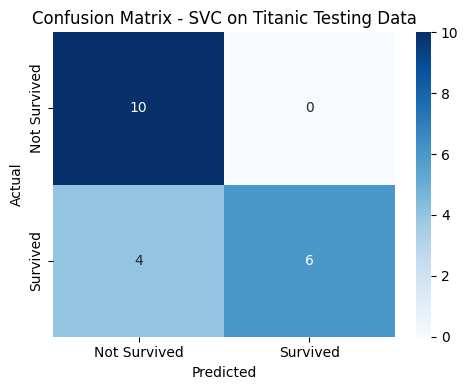

In [15]:
print('\nClassification Report:')
print('=======================\n')
print(classification_report(model_predictions['Survived'], model_predictions['Predictions'], target_names=['Not Survived (0)', 'Survived (1)']))
conf_matrix = confusion_matrix(model_predictions['Survived'], model_predictions['Predictions'])
conf_matrix_df = pd.DataFrame(conf_matrix, index=['Actual: Not Survived', 'Actual: Survived'], columns=['Predicted: Not Survived', 'Predicted: Survived'])
print('\nConfusion Matrix:')
print('==================\n')
print(conf_matrix_df)
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Survived', 'Survived'], yticklabels=['Not Survived', 'Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Titanic Testing Data')
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [16]:
pclass_input = 'First'
gender_input = 'Male'
sibling_input = 'Zero'
embarked_input = 'Queenstown'
print(f'PClass: {pclass_input}, Gender: {gender_input}, Sibling: {sibling_input}, Embarked: {embarked_input}')

PClass: First, Gender: Male, Sibling: Zero, Embarked: Queenstown


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [17]:
user_input = pd.DataFrame({'PClass': [pclass_input], 'Gender': [gender_input], 'Sibling': [sibling_input], 'Embarked': [embarked_input]})
print('\n\nUser Input Feature Vector:')
print('==========================\n')
print(user_input)



User Input Feature Vector:

  PClass Gender Sibling    Embarked
0  First   Male    Zero  Queenstown


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [18]:
unseen_data_features = user_input.copy()
unseen_data_features['PClass'] = pclass_label_encoder.transform(user_input['PClass'])
unseen_data_features['Gender'] = gender_label_encoder.transform(user_input['Gender'])
unseen_data_features['Sibling'] = sibling_label_encoder.transform(user_input['Sibling'])
unseen_data_features['Embarked'] = embarked_label_encoder.transform(user_input['Embarked'])
print('\n\nUser Input Encoded Feature Vector:')
print('==================================\n')
print(unseen_data_features)



User Input Encoded Feature Vector:

   PClass  Gender  Sibling  Embarked
0       0       1        3         1


### Step 8.4: Load the Saved Model

In [19]:
model = pickle.load(open('svc_trained_model.pkl', 'rb'))

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [20]:
predicted_survival = model.predict(unseen_data_features)
if predicted_survival[0] == 1:
    prediction = 'SURVIVED'
else:
    prediction = 'NOT SURVIVED'
pretty_table = PrettyTable()
pretty_table.add_column('       ** Prediction **       ', [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|            SURVIVED            |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

These are illustrative examples; no real reviewers or collected feedback are claimed.

In [21]:
example_feedback = pd.DataFrame({'Reviewer': ['Illustrative reviewer', 'Illustrative tester'], 'Case': ['A model predicts survived', 'A model predicts not survived'], 'Feedback': ['Verify the outcome before judging correctness.', 'Collect verified labels and review errors.']})
print(example_feedback.to_string(index=False))

             Reviewer                          Case                                       Feedback
Illustrative reviewer     A model predicts survived Verify the outcome before judging correctness.
  Illustrative tester A model predicts not survived     Collect verified labels and review errors.


#### Step 9.2: Make a List of Potential Improvements

In [22]:
improvements = ['Use the full Titanic dataset (~900 passengers) instead of the 100-row toy sample, so rare combinations (e.g. large families) are better represented', 'Add Age and Fare as numeric features - both are known strong predictors of survival', 'Try class-balanced or cross-validated evaluation, since the toy dataset may not be representative', 'Compare additional models (e.g. Random Forest, Gradient Boosting) beyond SVC/Logistic Regression/Decision Tree']
for i, item in enumerate(improvements, 1):
    print(f'{i}. {item}')

1. Use the full Titanic dataset (~900 passengers) instead of the 100-row toy sample, so rare combinations (e.g. large families) are better represented
2. Add Age and Fare as numeric features - both are known strong predictors of survival
3. Try class-balanced or cross-validated evaluation, since the toy dataset may not be representative
4. Compare additional models (e.g. Random Forest, Gradient Boosting) beyond SVC/Logistic Regression/Decision Tree


#### Step 9.3: Improve the Model Based on Feedback

In [23]:
print('Next version: retrain with Age + Fare features on the full dataset, then re-evaluate before replacing svc_trained_model.pkl')

Next version: retrain with Age + Fare features on the full dataset, then re-evaluate before replacing svc_trained_model.pkl


## Step 10: Deploy the Model as a Public Web App

The cloud demo linked above uses the exact trained SVC parameters. It is currently private. The included `app.py` loads `svc_trained_model.pkl` directly for Streamlit deployment.

1. Upload the contents of `titanic_deployment/` to a public GitHub repository.
2. Sign in at https://share.streamlit.io, choose the repository and branch `main`, and set the main file to `app.py`.
3. Select Python 3.12 and deploy. Keep `requirements.txt` beside `app.py`.
4. Verify predictions in the deployed form, then replace the first notebook cell with the public URL.

Local launch from the project folder:
```bash
python3 -m pip install -r requirements.txt
python3 -m streamlit run app.py
```

The instructor's existing demo is a reference and is not this student's deployment.


## Conclusion
The instructor's four-input SVC system has been executed with the provided 100-row sample. Step 7 gives the measured held-out accuracy and class-specific precision, recall and F1.

## Reference
Starter and sample: Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab, https://github.com/haqnawaz99/ml-teaching-notebooks.